In [ ]:
# Checking the data
DATA_DIR = "../test_data"
PLOTS_DIR = "../results/plots"
RESULTS_DIR = "../results"

In [2]:
# Imports
import os, glob, time
import numpy as np
import pandas as pd
import librosa, librosa.display
import pretty_midi
import matplotlib.pyplot as plt

In [ ]:
# Finding the wav + midi pairs in the data directory
os.makedirs(PLOTS_DIR, exist_ok=True)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def find_pairs(data_dir):
    midi_by_stem = {}
    for path in glob.glob(os.path.join(data_dir, "**", "*"), recursive=True):
        if os.path.isfile(path) and os.path.splitext(path)[1].lower() in (".mid", ".midi"):
            stem = os.path.normcase(os.path.splitext(path)[0])
            midi_by_stem[stem] = path

    pairs = []
    for wav in sorted(glob.glob(os.path.join(data_dir, "**", "*.wav"), recursive=True)):
        stem = os.path.normcase(os.path.splitext(wav)[0])
        if stem in midi_by_stem:
            pairs.append((wav, midi_by_stem[stem]))
    return pairs

pairs = find_pairs(DATA_DIR)
print(f"Found {len(pairs)} WAV + MIDI pairs")
if not pairs:
    print(f"Warning: no matching files found under {os.path.abspath(DATA_DIR)}. Check DATA_DIR and the file locations.")

Found 10 WAV + MIDI pairs


In [ ]:
# Loading the first pair of wav and midi files
wav_path, midi_path = pairs[0]
y, sr = librosa.load(wav_path, sr=None, mono=False)
print("File:", os.path.basename(wav_path))
print("Sample rate:", sr, "Hz")
print("Channels:", 1 if y.ndim == 1 else y.shape[0])
print("Duration:", round(y.shape[-1] / sr, 1), "seconds")

File: MIDI-Unprocessed_01_R1_2006_01-09_ORIG_MID--AUDIO_01_R1_2006_05_Track05_wav.wav
Sample rate: 44100 Hz
Channels: 2
Duration: 434.9 seconds


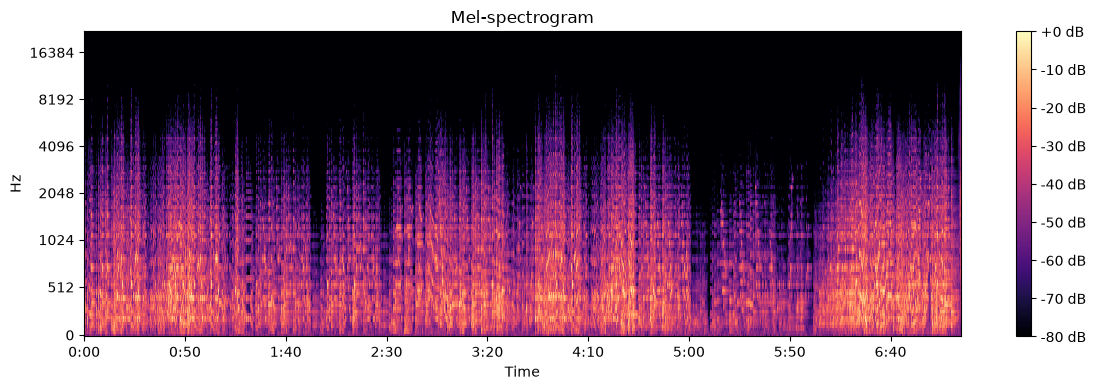

In [6]:
# Plotting the mel-spectrogram of the audio
mono = librosa.to_mono(y) if y.ndim > 1 else y
mel = librosa.feature.melspectrogram(y=mono, sr=sr, n_mels=128, hop_length=512)
mel_db = librosa.power_to_db(mel, ref=np.max)   # fine for looking, NOT for the model

fig, ax = plt.subplots(figsize=(12, 4))
img = librosa.display.specshow(mel_db, sr=sr, hop_length=512, x_axis="time", y_axis="mel", ax=ax)
fig.colorbar(img, ax=ax, format="%+2.0f dB")
ax.set_title("Mel-spectrogram")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "01_mel_spectrogram.png"), dpi=120)
plt.show()

In [ ]:
# Loading the MIDI file and printing some statistics
pm = pretty_midi.PrettyMIDI(midi_path)
notes = [n for inst in pm.instruments for n in inst.notes]
velocities = np.array([n.velocity for n in notes])
starts = np.array([n.start for n in notes])

print("Notes:", len(notes))
print("Velocity min / mean / max:", velocities.min(), round(velocities.mean(), 1), velocities.max())

_, tempos = pm.get_tempo_changes()
print("Tempo markers:", np.round(tempos, 1)[:10])
if len(np.unique(np.round(tempos))) == 1:
    print("-> Only one value. It's a placeholder, not the real tempo.")

Notes: 5126
Velocity min / mean / max: 3 68.7 123
Tempo markers: [120.]
-> Only one value. It's a placeholder, not the real tempo.


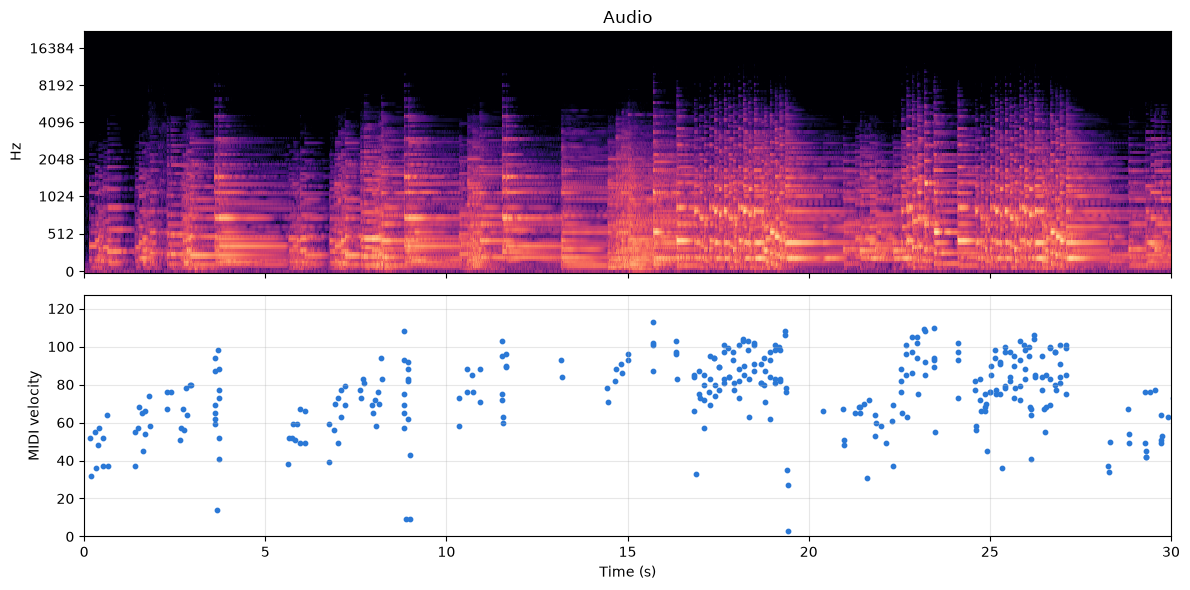

In [8]:
# Plotting the audio and MIDI velocity over time
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
librosa.display.specshow(mel_db, sr=sr, hop_length=512, x_axis="time", y_axis="mel", ax=ax1)
ax1.set_title("Audio"); ax1.set_xlabel("")
ax2.scatter(starts, velocities, s=10, color=BLUE)
ax2.set_ylabel("MIDI velocity"); ax2.set_xlabel("Time (s)"); ax2.set_ylim(0, 127); ax2.grid(alpha=0.3)
ax1.set_xlim(0, 30)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "01_audio_vs_velocity.png"), dpi=120)
plt.show()

In [9]:
# Calculating the correlation between audio loudness and MIDI velocity
rms_db = librosa.amplitude_to_db(librosa.feature.rms(y=mono, hop_length=sr)[0] + 1e-9)   # one loudness value per second
# mean velocity of the notes starting in each second
sec_vel = np.array([velocities[(starts >= i) & (starts < i+1)].mean()
                    if np.any((starts >= i) & (starts < i+1)) else np.nan
                    for i in range(len(rms_db))])
ok = ~np.isnan(sec_vel)
r = np.corrcoef(rms_db[ok], sec_vel[ok])[0, 1]
print(f"Loudness vs velocity: r = {r:.2f}  (above ~0.5 = aligned)")

Loudness vs velocity: r = 0.73  (above ~0.5 = aligned)
